Exact Solution:
Exact landing time: 1.0096375546923044 s
Exact landing speed: 9.904544411531507 m/s

Forward Euler Method
dt = 0.1 s
Landing time = 1.1000 s
Landing speed = 10.7910 m/s
Time error = 8.9500 %
Speed error = 8.9500 %
dt = 0.05 s
Landing time = 1.0500 s
Landing speed = 10.3005 m/s
Time error = 3.9977 %
Speed error = 3.9977 %
dt = 0.01 s
Landing time = 1.0200 s
Landing speed = 10.0062 m/s
Time error = 1.0264 %
Speed error = 1.0264 %

Euler Cromer Method
dt = 0.1 s
Landing time = 1.0000 s
Landing speed = 9.8100 m/s
Time error = -0.9546 %
Speed error = -0.9546 %
dt = 0.05 s
Landing time = 1.0000 s
Landing speed = 9.8100 m/s
Time error = -0.9546 %
Speed error = -0.9546 %
dt = 0.01 s
Landing time = 1.0100 s
Landing speed = 9.9081 m/s
Time error = 0.0359 %
Speed error = 0.0359 %

Velocity Verlet method
dt = 0.1 s
Landing time = 1.1000 s
Landing speed = 10.7910 m/s
Time error = 8.9500 %
Speed error = 8.9500 %
dt = 0.05 s
Landing time = 1.0500 s
Landing speed = 10.3005 m/s
Time err

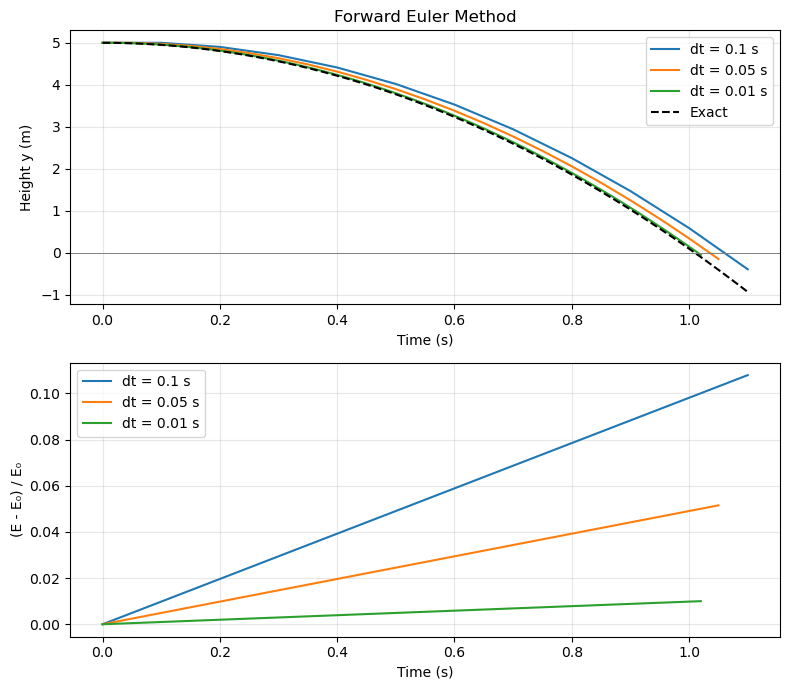

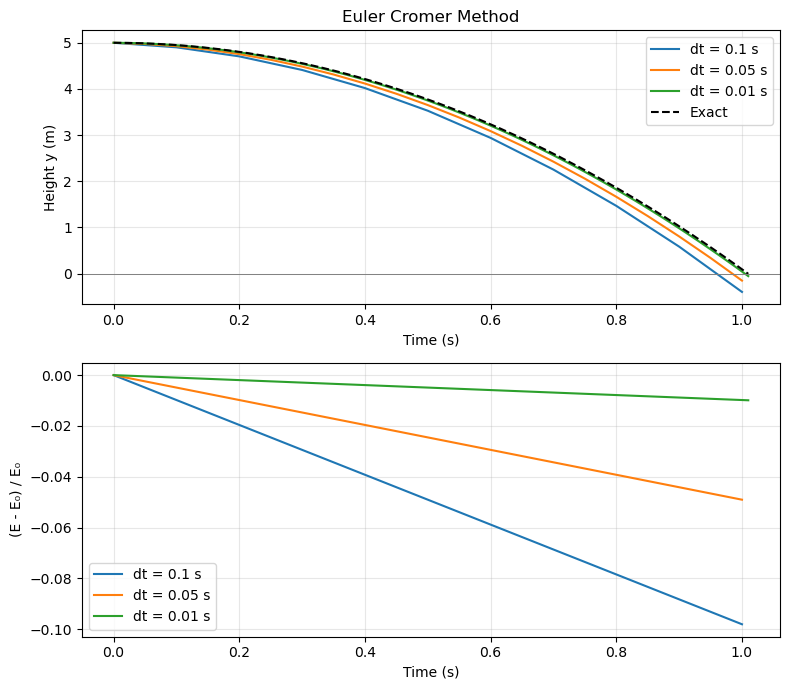

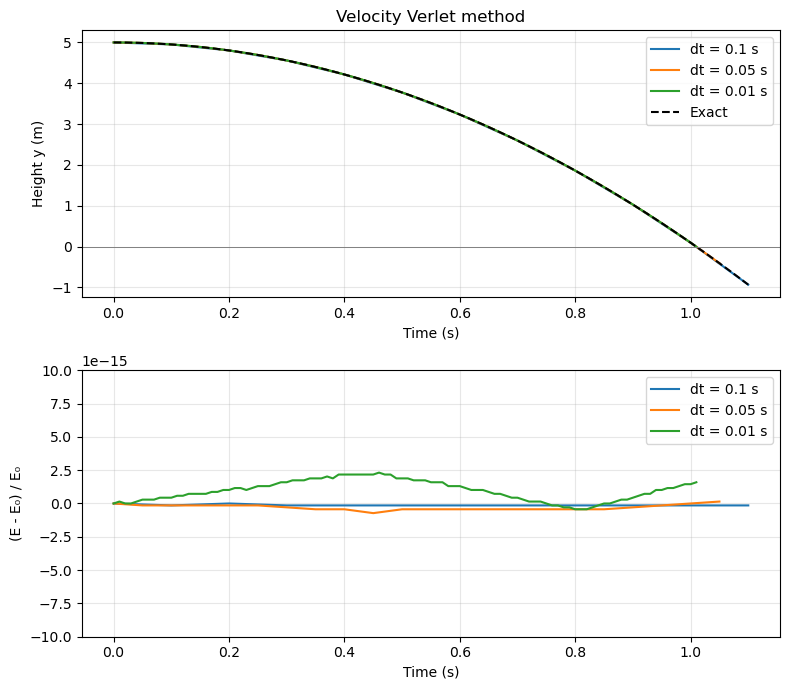

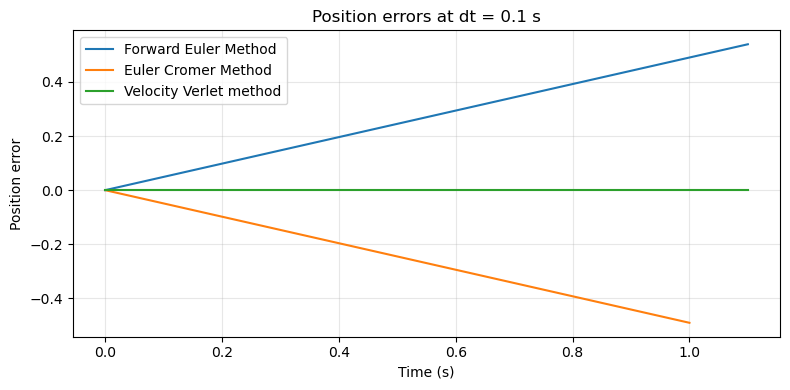

Forward Euler Method
dt = 0.1 s
Relative energy error at 20 s: +1.899052755e+08
Percentage energy error: +1.899052755e+10 %
dt = 0.05 s
Relative energy error at 20 s: +1.947708051e+04
Percentage energy error: +1.947708051e+06 %
dt = 0.01 s
Relative energy error at 20 s: +6.381675654e+00
Percentage energy error: +6.381675654e+02 %

Euler Cromer Method
dt = 0.1 s
Relative energy error at 20 s: -1.363116298e-01
Percentage energy error: -1.363116298e+01 %
dt = 0.05 s
Relative energy error at 20 s: -6.226504310e-02
Percentage energy error: -6.226504310e+00 %
dt = 0.01 s
Relative energy error at 20 s: -1.161585006e-02
Percentage energy error: -1.161585006e+00 %

Velocity Verlet method
dt = 0.1 s
Relative energy error at 20 s: -9.890207802e-03
Percentage energy error: -9.890207802e-01 %
dt = 0.05 s
Relative energy error at 20 s: -1.331556769e-03
Percentage energy error: -1.331556769e-01 %
dt = 0.01 s
Relative energy error at 20 s: -4.088723694e-05
Percentage energy error: -4.088723694e-03 %



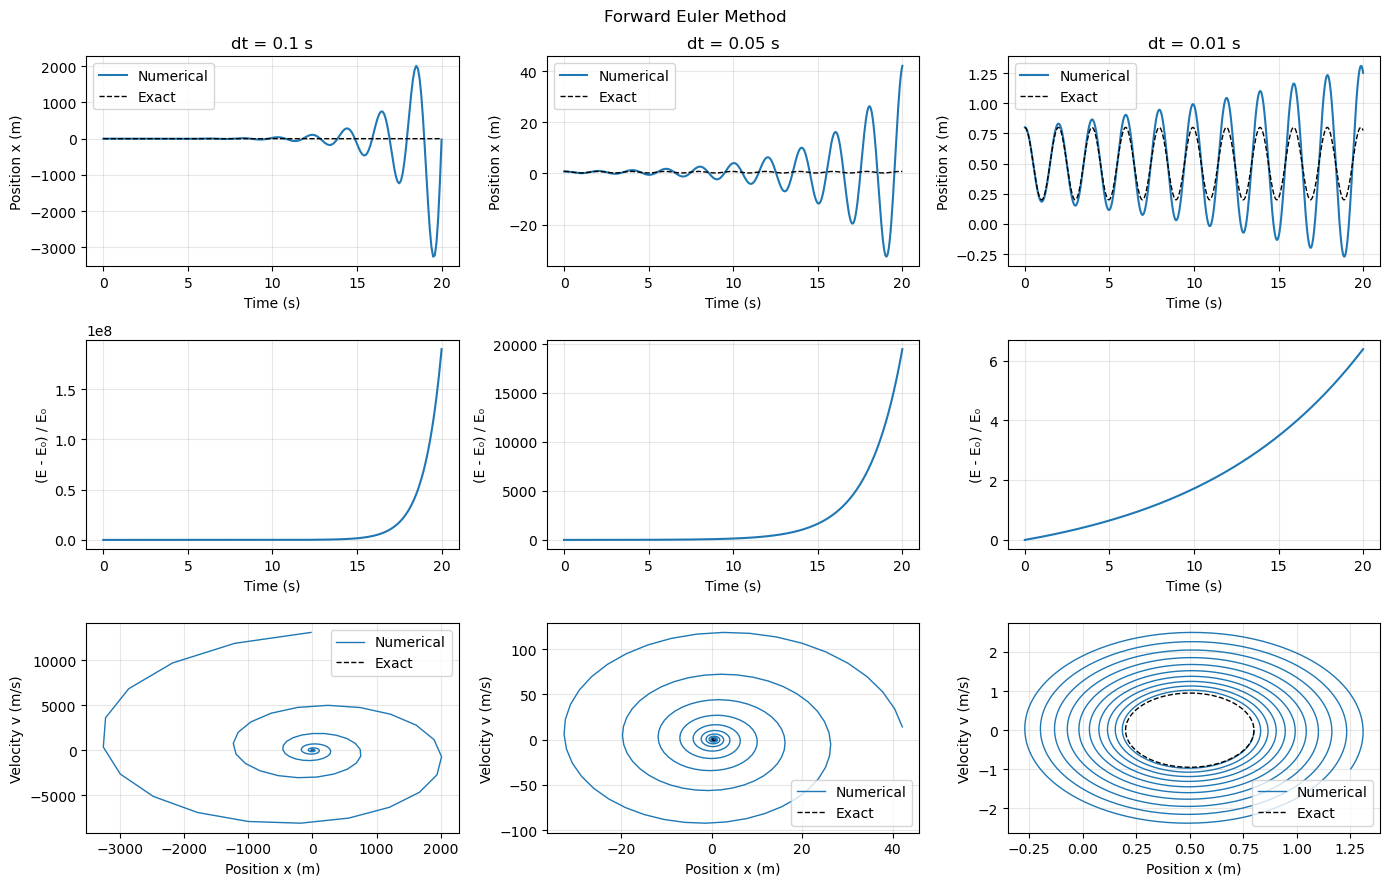

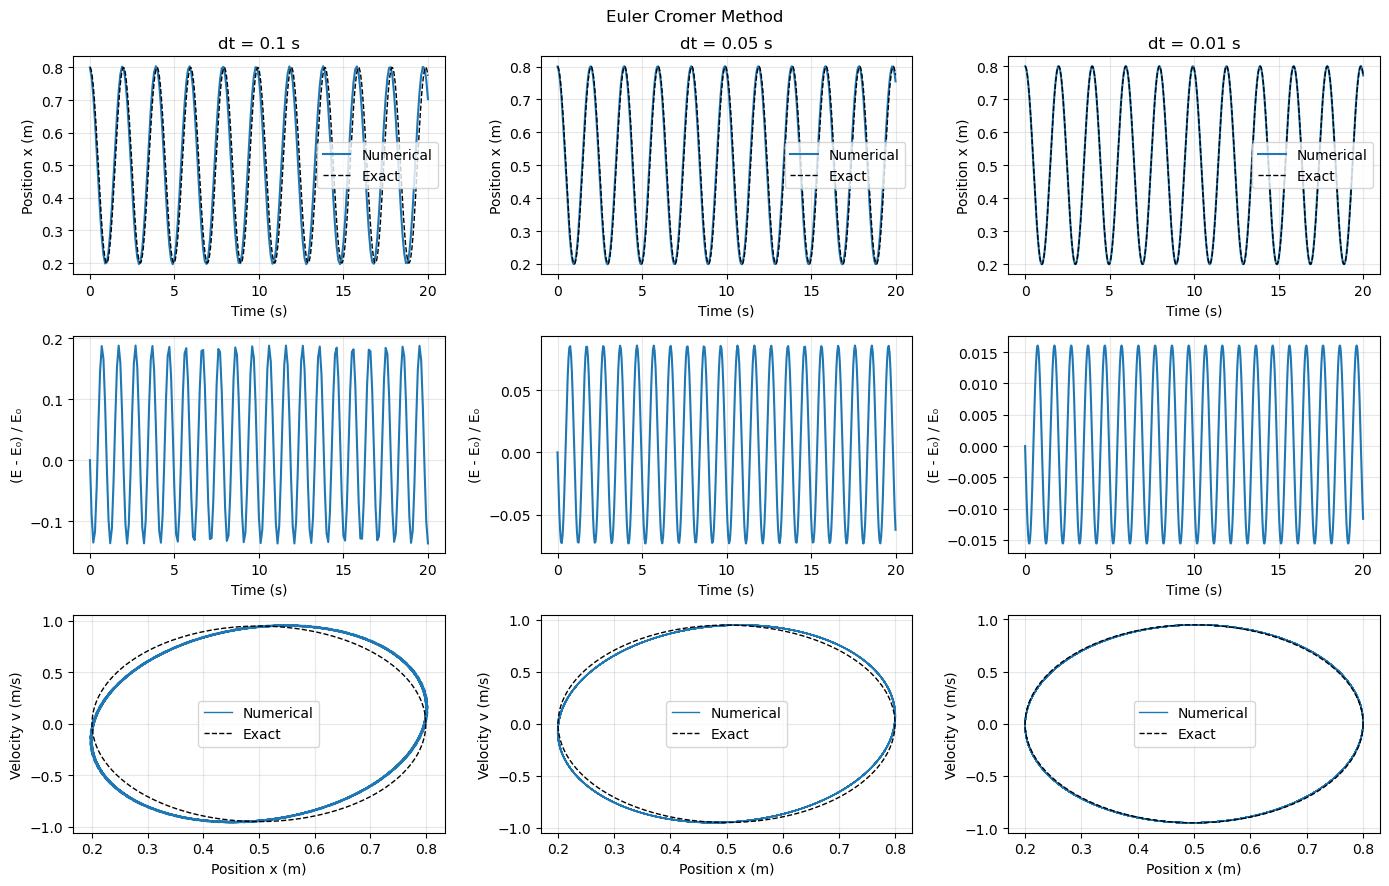

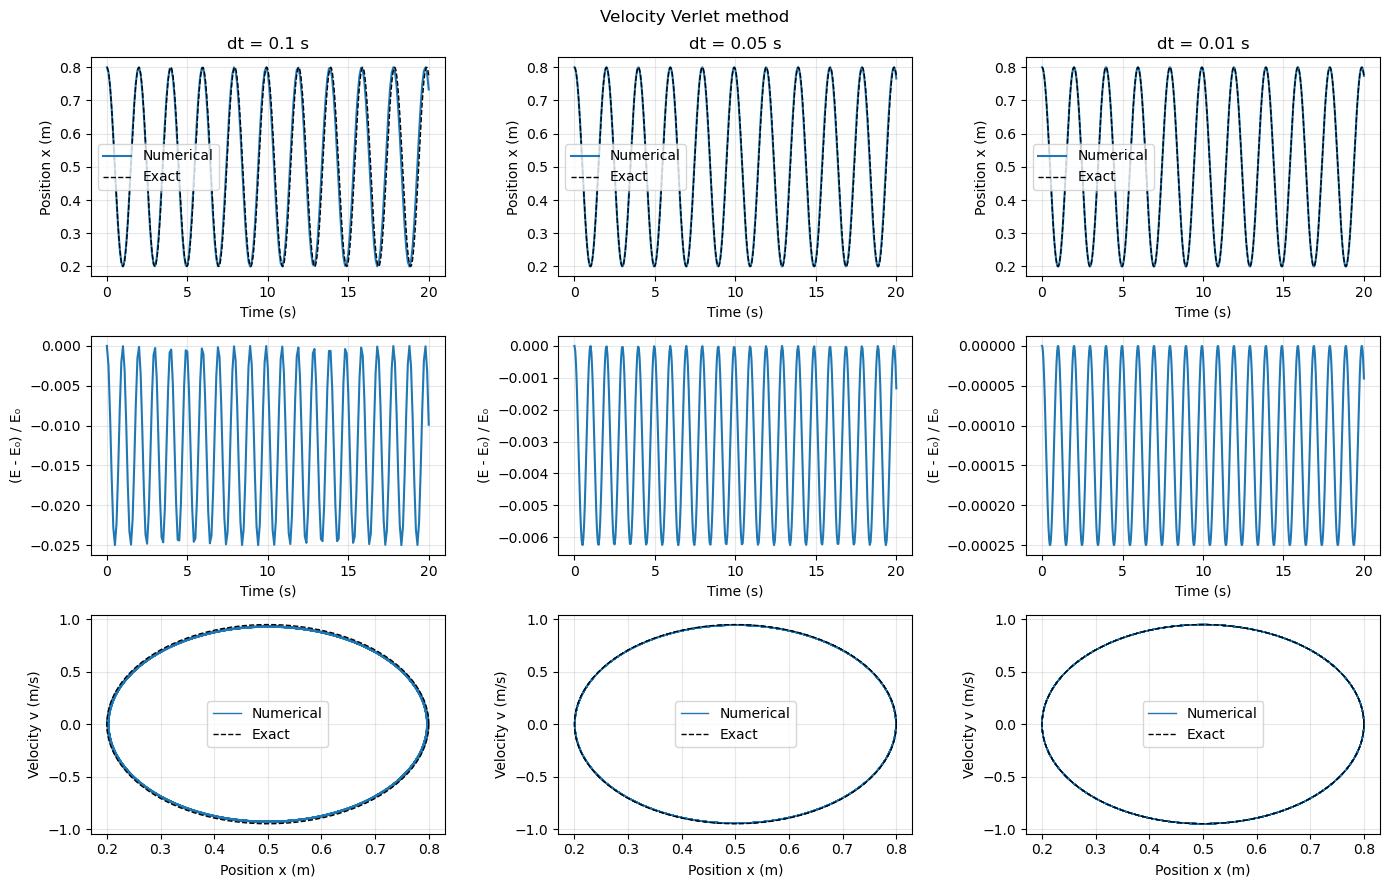

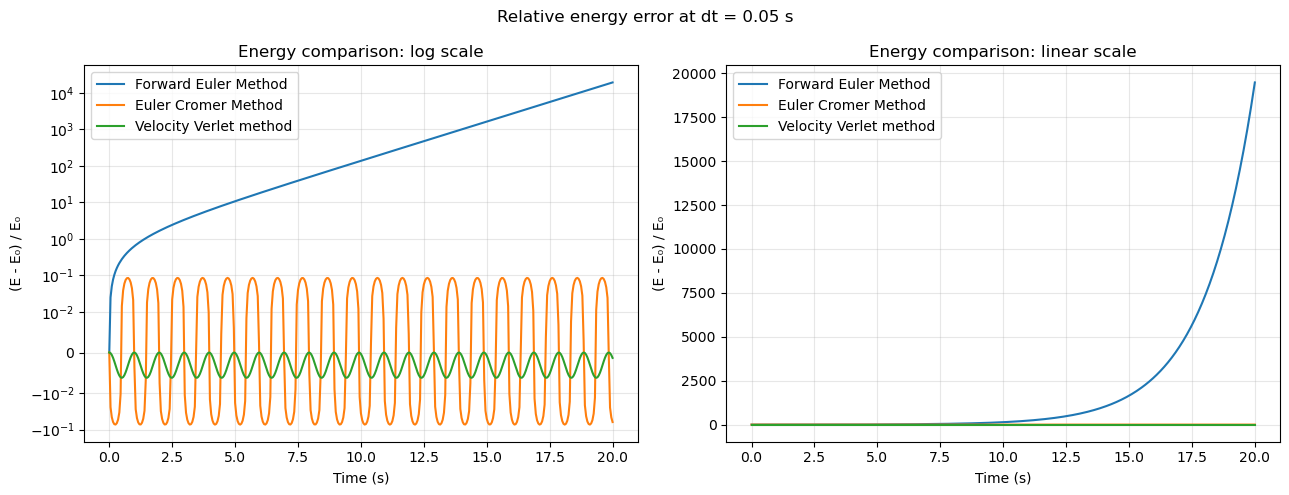

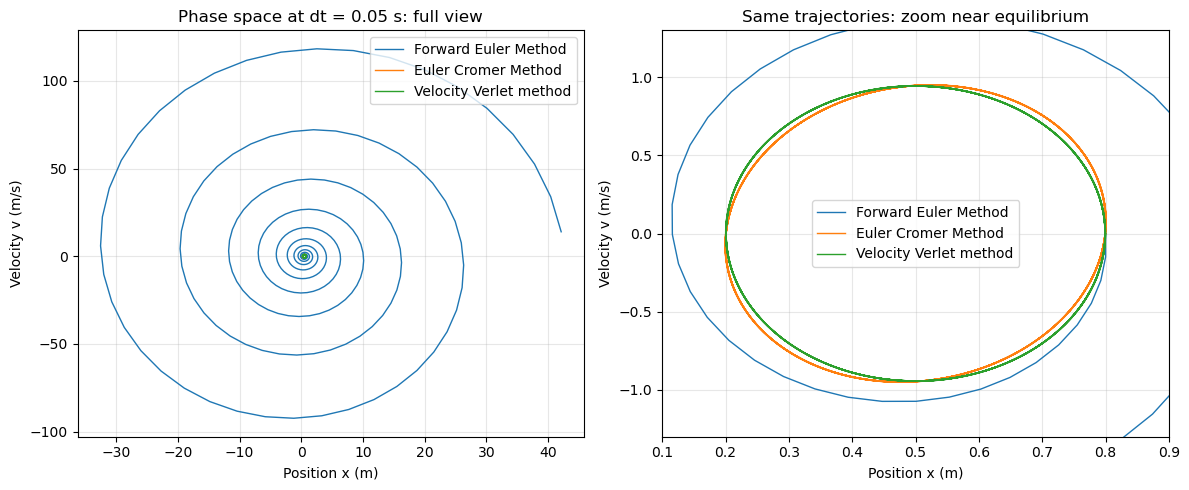

Measured Verlet period at dt = 0.01 s: 1.986834856 s
Period error: -0.004167%

Tested Forward Euler E₂₀/E₀ at dt = 0.01 s: 7.381675654
Tested minus predicted ratio: +1.632e-12

Exact period: 1.986917653 s
Initial energy: 2.250000 J
Predicted Forward Euler E₂₀/E₀ at dt = 0.01 s: 7.381675654
Spring 1 initial force (N): [-15.  -0.]
Spring 2 initial force (N): [-2.13760611  3.56267686]
Spring 3 initial force (N): [-2.90569415  8.71708245]
Initial total force (N): [-20.04330026  12.27975931]

Forward Euler
dt = 0.05 s: maximum energy error = 3530300458562.326660%
dt = 0.01 s: maximum energy error = 1520.579562%
dt = 0.001 s: maximum energy error = 37.952456%
None of the requested steps keeps energy error below 1%
First distance above 1 cm: 0.55 s

Euler Cromer
dt = 0.05 s: maximum energy error = 12.215576%
dt = 0.01 s: maximum energy error = 2.231719%
dt = 0.001 s: maximum energy error = 0.224584%
Largest passing requested step: 0.001 s
Total-force evaluations: 20000
Distance does not excee

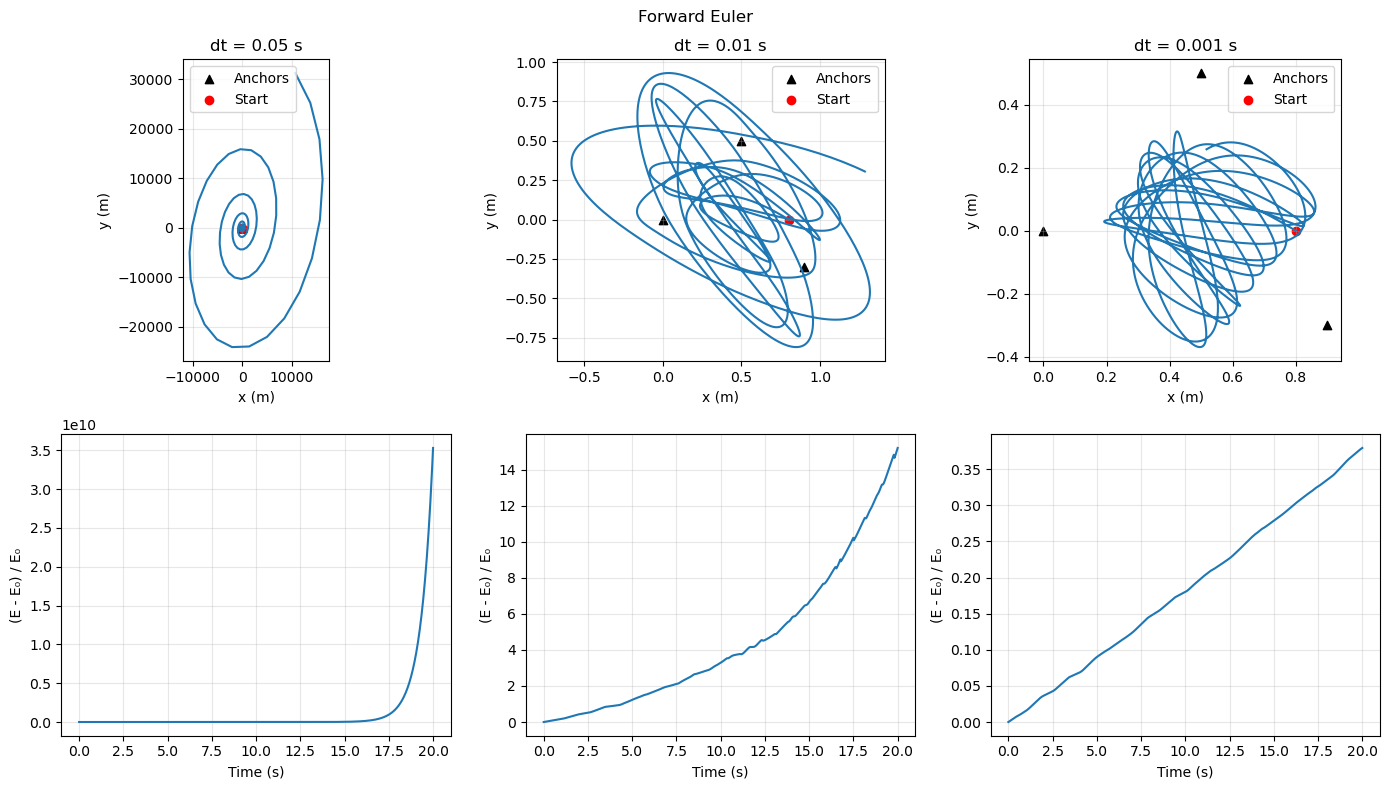

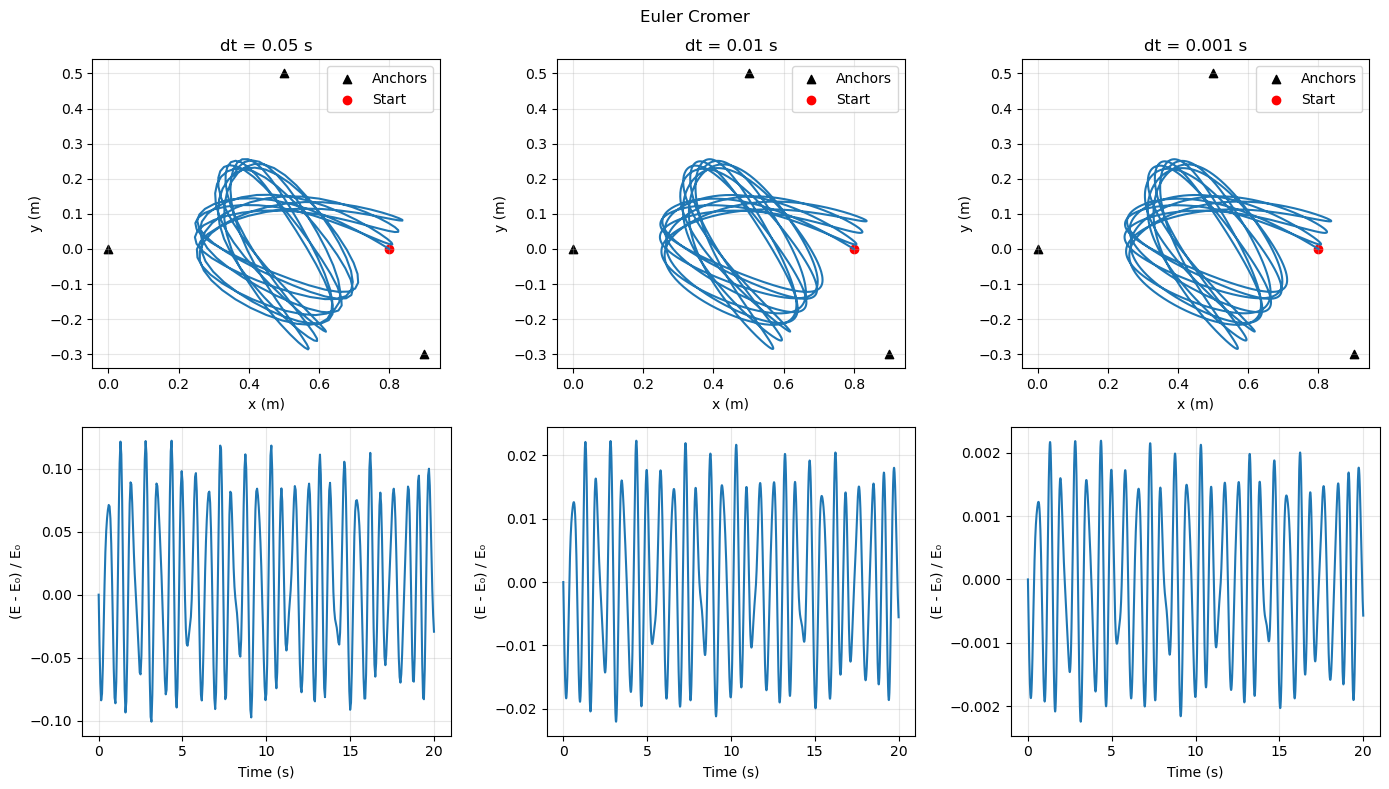

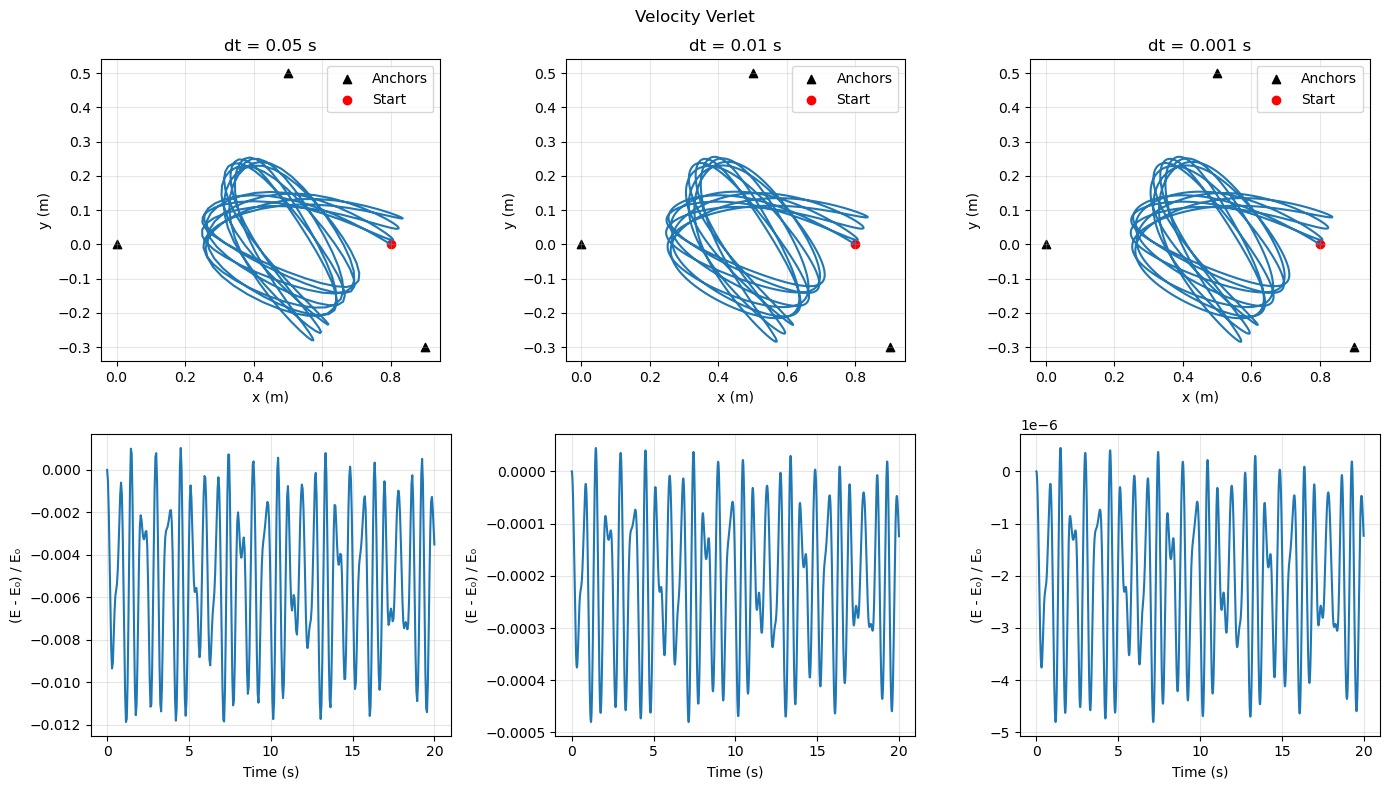

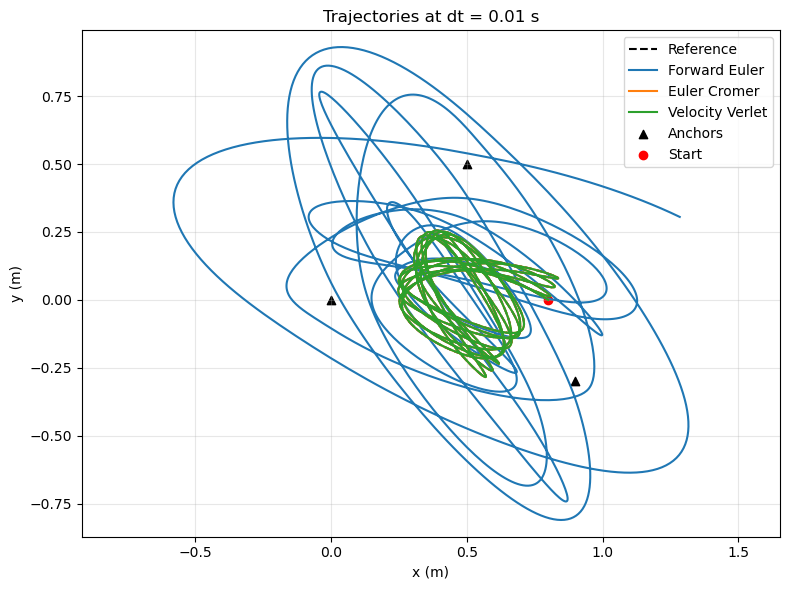

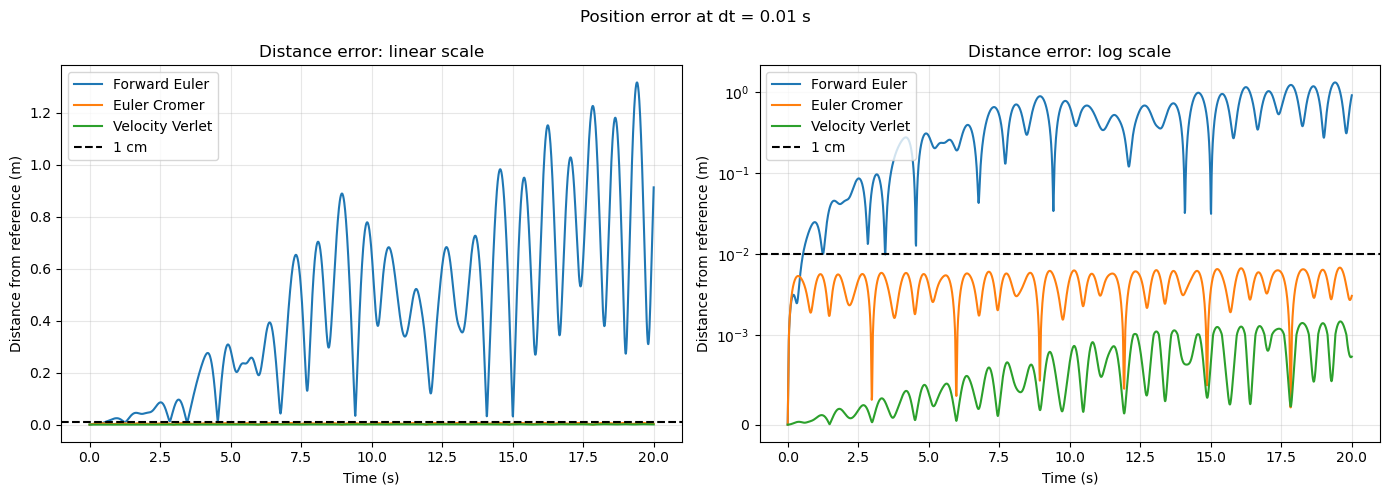

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def forward_euler(r, v, dt, acceleration):
    r_new = r + v * dt
    v_new = v + acceleration(r) * dt
    return r_new, v_new

def euler_cromer(r, v, dt, acceleration):
    v_new = v + acceleration(r) * dt
    r_new = r + v_new * dt
    return r_new, v_new

def velocity_verlet(r, v, dt, acceleration):
    r_new = r + v * dt + 0.5 * acceleration(r) * dt**2
    v_new = v + 0.5 * (acceleration(r) + acceleration(r_new)) * dt
    return r_new, v_new

#Problem 1: Free fall
g = 9.81
m = 1.00
y_0 = 5.00
time_steps = [0.1, 0.05, 0.01]
methods = [forward_euler, euler_cromer, velocity_verlet]
names = ["Forward Euler Method", "Euler Cromer Method", "Velocity Verlet method"]

def gravity(r):
    return -g

#exact solution: y(t) = y_0 + 0.5 * g * t^2
exact_total_time = np.sqrt(2 * y_0 / g)
exact_max_speed = g * exact_total_time

def simulate(method, dt):
    y = y_0
    v = 0.00
    T = [0.00]
    Y = [y]
    V = [v]
    n = 0
    
    while y > 0:
        y, v = method(y, v, dt, gravity)
        n += 1
        T.append(n * dt)
        Y.append(y)
        V.append(v)
        
    t = np.array(T)
    y = np.array(Y)
    v = np.array(V)
    energy = 0.5 * m * v**2 + m * g * y
    relative_energy_error = (energy - energy[0]) / energy[0]
    return t, y, v, relative_energy_error

runs = {}

for i, method in enumerate(methods):
    for j, dt in enumerate(time_steps):
        runs[i, j] = simulate(method, dt)

for i, name in enumerate(names):
    fig, axes = plt.subplots(2, 1, figsize=(8, 7))
    for j, dt in enumerate(time_steps):
        t, y, v, energy_error = runs[i, j]
        axes[0].plot(t, y, label=f'dt = {dt} s')
        axes[1].plot(t, energy_error, label=f'dt = {dt} s')

    end_time = max(runs[i, j][0][-1] for j in range(3))
    t_exact = np.linspace(0, end_time, 300)
    axes[0].plot(t_exact, y_0 - 0.5 * g * t_exact**2, 'k--', label='Exact')
    axes[0].axhline(0, color='gray', linewidth=0.7)
    axes[0].set_ylabel('Height y (m)')
    axes[0].set_title(name)
    axes[1].set_ylabel('(E - E\u2080) / E\u2080')
    if i == 2:
        axes[1].set_ylim(-1e-14, 1e-14)
    for ax in axes:
        ax.set_xlabel('Time (s)')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(f'{name}1.png')
    
STYLE = "\033[1;3;4m"
RESET = "\033[0m"

print(f"{STYLE}Exact Solution:{RESET}")
print('Exact landing time:', exact_total_time, 's')
print('Exact landing speed:', exact_max_speed, 'm/s')
print()

for name, method in zip(names, methods):
    print(f"{STYLE}{name}{RESET}")

    for dt in time_steps:
        t, y, v, energy_error = simulate(method, dt)
        
        landing_time = t[-1]
        landing_speed = abs(v[-1])
        speed_error = 100 * (landing_speed - exact_max_speed) / exact_max_speed 
        time_error = 100 * (landing_time - exact_total_time) / exact_total_time
        
        print(f"dt = {dt} s")
        print(f"Landing time = {landing_time:.4f} s")
        print(f"Landing speed = {landing_speed:.4f} m/s")
        print(f"Time error = {time_error:.4f} %")
        print(f"Speed error = {speed_error:.4f} %")
    print()

plt.figure(figsize=(8, 4))
for i, name in enumerate(names):
    t, y, v, energy_error = runs[i, 0]
    position_error = y - (y_0 - 0.5 * g * t**2)
    plt.plot(t, position_error, label=name)
plt.xlabel('Time (s)')
plt.ylabel('Position error')
plt.title('Position errors at dt = 0.1 s')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('position_error.png')
plt.show()

#Problem 2: Mass on a spring
m = 5.00
k = 50
l_eq = 0.5
x_0 = 0.8
w = np.sqrt(k / m)
time = 20
t_period = 2 * np.pi / w
amplitude = x_0 - l_eq
E_0 = 0.5 * k * amplitude**2

time_steps = [0.1, 0.05, 0.01]
methods = [forward_euler, euler_cromer, velocity_verlet]
names = ["Forward Euler Method", "Euler Cromer Method", "Velocity Verlet method"]

def acceleration(x):
    a = -k * (x - l_eq) / m
    return a

def simulate(method, dt):
    steps = round(time / dt)
    t = np.arange(steps + 1) * dt
    x = np.zeros(steps + 1)
    v = np.zeros(steps + 1)
    x[0] = x_0
    
    for n in range(steps):
        x[n+1], v[n+1] = method(x[n], v[n], dt, acceleration)
    
    energy = 0.5 * m * v**2 + 0.5 * k * (x - l_eq)**2
    return t, x, v, energy

STYLE = "\033[1;3;4m"
RESET = "\033[0m"

runs = {}
for i, method in enumerate(methods):
    print(f"{STYLE}{names[i]}{RESET}")
    for j, dt in enumerate(time_steps):
        t, x, v, energy = simulate(method, dt)
        runs[i, j] = (t, x, v, energy)
        relative_error = (energy[-1] - E_0) / E_0
        print(f'dt = {dt} s')
        print(f'Relative energy error at 20 s: {relative_error:+.9e}')
        print(f'Percentage energy error: {100 * relative_error:+.9e} %')
    print()

t_exact = np.linspace(0, time, 3000)
x_exact = l_eq + amplitude * np.cos(w * t_exact)
phase = np.linspace(0, 2 * np.pi, 400)

for i, name in enumerate(names):
    fig, axes = plt.subplots(3, 3, figsize=(14, 9))
    fig.suptitle(name)

    for j, dt in enumerate(time_steps):
        t, x, v, energy = runs[i, j]
        relative_error = (energy - E_0) / E_0

        axes[0, j].plot(t, x, label='Numerical')
        axes[0, j].plot(t_exact, x_exact, 'k--', label='Exact', linewidth=1)
        axes[0, j].set_title(f'dt = {dt} s')
        axes[0, j].set_xlabel('Time (s)')
        axes[0, j].set_ylabel('Position x (m)')
        axes[0, j].legend()

        axes[1, j].plot(t, relative_error)
        axes[1, j].set_xlabel('Time (s)')
        axes[1, j].set_ylabel('(E - E\u2080) / E\u2080')

        #axes[2, j].plot(x, v)
        axes[2, j].plot(x, v, label='Numerical', linewidth=1)
        axes[2, j].plot(l_eq + amplitude * np.cos(phase), -amplitude * w * np.sin(phase), 'k--', label='Exact', linewidth=1)
        axes[2, j].set_xlabel('Position x (m)')
        axes[2, j].set_ylabel('Velocity v (m/s)')
        axes[2, j].legend()

    for ax in axes.flat:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f'{name}2.png')
    
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i, name in enumerate(names):
    t, x, v, energy = runs[i, 1]
    relative_error = (energy - E_0) / E_0
    for ax in axes:
        ax.plot(t, relative_error, label=name)
axes[0].set_yscale("symlog", linthresh=0.01)
axes[0].set_title("Energy comparison: log scale")
axes[1].set_title("Energy comparison: linear scale")
for ax in axes:
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("(E - E\u2080) / E\u2080")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Relative energy error at dt = 0.05 s")
fig.tight_layout()
fig.savefig('relative_error2.png')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, name in enumerate(names):
    t, x, v, energy = runs[i, 1]
    for ax in axes:
        ax.plot(x, v, label=name, linewidth=1)

axes[0].set_title('Phase space at dt = 0.05 s: full view')
axes[1].set_title('Same trajectories: zoom near equilibrium')
axes[1].set_xlim(0.1, 0.9)
axes[1].set_ylim(-1.3, 1.3)
for ax in axes:
    ax.set_xlabel('Position x (m)')
    ax.set_ylabel('Velocity v (m/s)')
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig('phase_space2.png')
plt.show()

t, x, v, energy = runs[2, 2]
crossings = []
for n in range(len(t) - 1):
    if x[n] > l_eq and x[n + 1] <= l_eq:
        fraction = (x[n] - l_eq) / (x[n] - x[n + 1])
        crossings.append(t[n] + fraction * (t[n + 1] - t[n]))

measured_period = np.mean(np.diff(crossings))
print(f'Measured Verlet period at dt = 0.01 s: {measured_period:.9f} s')
print(f'Period error: {100 * (measured_period - t_period) / t_period:+.6f}%')
print()

tested_ratio = runs[0, 2][3][-1] / E_0
predicted_ratio = (1 + w**2 * 0.01**2)**round(time / 0.01)
print(f'Tested Forward Euler E\u2082\u2080/E\u2080 at dt = 0.01 s: {tested_ratio:.9f}')
print(f'Tested minus predicted ratio: {tested_ratio - predicted_ratio:+.3e}')
print()

predicted_ratio = (1 + w**2 * 0.01**2)**round(time / 0.01)
print(f'Exact period: {t_period:.9f} s')
print(f'Initial energy: {E_0:.6f} J')
print(f'Predicted Forward Euler E\u2082\u2080/E\u2080 at dt = 0.01 s: {predicted_ratio:.9f}')

#Problem 3: Mass held by three springs
m = 5.0          # kg
k = 50.0         # N/m
l_eq = 0.5       # m
time = 20.0  # s
r_0 = np.array([0.8, 0.0])
anchors = np.array([[0.0, 0.0], [0.5, 0.5], [0.9, -0.3]])

time_steps = [0.05, 0.01, 0.001]
names = ['Forward Euler', 'Euler Cromer', 'Velocity Verlet']
methods = [forward_euler, euler_cromer, velocity_verlet]

STYLE = "\033[1;3;4m"
RESET = "\033[0m"

def spring_force(r, anchor, stiffness):
    displacement = r - anchor
    length = np.linalg.norm(displacement)
    return -stiffness * (length - l_eq) * displacement / length


def total_force(r, stiffness):
    force = np.zeros(2)
    for anchor in anchors:
        force += spring_force(r, anchor, stiffness)
    return force


def simulate(method, dt, stiffness=50.0):
    steps = int(np.ceil(time / dt))
    dt = time / steps
    t = np.arange(steps + 1) * dt
    r = np.zeros((steps + 1, 2))
    v = np.zeros((steps + 1, 2))
    r[0] = r_0

    def acceleration(position):
        return total_force(position, stiffness) / m

    for n in range(steps):
        r[n + 1], v[n + 1] = method(r[n], v[n], dt, acceleration)

    energy = 0.5 * m * np.sum(v**2, axis=1)
    for anchor in anchors:
        lengths = np.linalg.norm(r - anchor, axis=1)
        energy += 0.5 * stiffness * (lengths - l_eq)**2

    return t, r, v, energy


# Initial force from each spring
for i, anchor in enumerate(anchors):
    print(f'Spring {i + 1} initial force (N):', spring_force(r_0, anchor, k))
print('Initial total force (N):', total_force(r_0, k))
print()
# Reference solution
reference_dt = 0.0001
t_ref, r_ref, v_ref, energy_ref = simulate(velocity_verlet, reference_dt)

runs = {}
distances = {}
best_steps = [None, None, None]

for i, method in enumerate(methods):
    print(f"{STYLE}{names[i]}{RESET}")

    for j, dt in enumerate(time_steps):
        t, r, v, energy = simulate(method, dt)
        runs[i, j] = t, r, v, energy
        error = (energy - energy[0]) / energy[0]
        max_error = np.max(np.abs(error))
        print(f'dt = {dt} s: maximum energy error = {100 * max_error:.6f}%')

        stride = round(dt / reference_dt)
        distances[i, j] = np.linalg.norm(r - r_ref[::stride], axis=1)

        if max_error < 0.01 and best_steps[i] is None:
            best_steps[i] = dt
            steps = len(t) - 1
            force_count = 2 * steps if method == velocity_verlet else steps
            print(f'Largest passing requested step: {dt} s')
            print(f'Total-force evaluations: {force_count}')

    if best_steps[i] is None:
        print('None of the requested steps keeps energy error below 1%')

    t = runs[i, 1][0]
    crossing_found = False
    for n in range(len(t)):
        if distances[i, 1][n] > 0.01:
            print(f'First distance above 1 cm: {t[n]:.2f} s')
            crossing_found = True
            break
    if not crossing_found:
        print('Distance does not exceed 1 cm within 20 s at dt = 0.01 s')
    print()

predicted_dt = best_steps[2] / np.sqrt(2)
print(f'Predicted Velocity Verlet step for k = 100 N/m: {predicted_dt:.9f} s')
t, r, v, energy = simulate(velocity_verlet, predicted_dt, stiffness=100)
error = (energy - energy[0]) / energy[0]
print(f'Actual step adjusted to end at 20 s: {t[1]:.9f} s')
print(f'Maximum energy error at this step: {100 * np.max(np.abs(error)):.6f}%')
print()
print(f'{STYLE}Testing the original step sizes with k = 100 N/m:{RESET}')
best_doubled = None
for dt in time_steps:
    t, r, v, energy = simulate(velocity_verlet, dt, stiffness=100)
    max_error = np.max(np.abs((energy - energy[0]) / energy[0]))
    print(f'dt = {dt} s: maximum energy error = {100 * max_error:.6f}%')
    if max_error < 0.01 and best_doubled is None:
        best_doubled = dt
print()
print('Largest passing requested step at k = 100 N/m:', best_doubled)

for i, name in enumerate(names):
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    fig.suptitle(name)

    for j, dt in enumerate(time_steps):
        t, r, v, energy = runs[i, j]
        axes[0, j].plot(r[:, 0], r[:, 1])
        axes[0, j].scatter(anchors[:, 0], anchors[:, 1], marker='^', color='black', label='Anchors')
        axes[0, j].scatter(r_0[0], r_0[1], color='red', label='Start')
        axes[0, j].set_title(f'dt = {dt} s')
        axes[0, j].set_xlabel('x (m)')
        axes[0, j].set_ylabel('y (m)')
        axes[0, j].set_aspect('equal', adjustable='box')
        axes[0, j].legend()

        axes[1, j].plot(t, (energy - energy[0]) / energy[0])
        axes[1, j].set_xlabel('Time (s)')
        axes[1, j].set_ylabel('(E - E\u2080) / E\u2080')

    for ax in axes.flat:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f'{name}3.png')

plt.figure(figsize=(8, 6))
plt.plot(r_ref[:, 0], r_ref[:, 1], 'k--', label='Reference')
for i, name in enumerate(names):
    t, r, v, energy = runs[i, 1]
    plt.plot(r[:, 0], r[:, 1], label=name)
plt.scatter(anchors[:, 0], anchors[:, 1], marker='^', color='black', label='Anchors')
plt.scatter(r_0[0], r_0[1], color='red', label='Start')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Trajectories at dt = 0.01 s')
plt.axis('equal')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('reftraj3.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, name in enumerate(names):
    t = runs[i, 1][0]

    for ax in axes:
        ax.plot(t, distances[i, 1], label=name)
axes[0].set_title("Distance error: linear scale")
axes[1].set_yscale("symlog", linthresh=0.001)
axes[1].set_title("Distance error: log scale")
for ax in axes:
    ax.axhline(0.01, color="black", linestyle="--", label="1 cm")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Distance from reference (m)")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Position error at dt = 0.01 s")
fig.tight_layout()
fig.savefig('PE3')
plt.show()